# Дослідження даних, Ridge M2 та сегментний аналіз

## Підхід

Аналіз виконується на розпарсених річних звітах до фільтрації модельної популяції та на панелі з горизонтом прогнозу один рік. Аномалії не видаляються: вони додаються як ознаки, а якість окремо оцінюється на всій і «чистій» популяціях. M2 прогнозує зміну логарифма доходу, використовує лише інформацію, доступну до року цілі, та перевіряється часовими фолдами F1–F2.

## 1. Завантаження даних

### Підхід

Завантажуються спільні артефакти `reports_all.parquet` і `panel_v1.parquet`. Перевіряється, що максимальний рік цілі — 2024 і holdout 2025 не прочитаний.

In [9]:
!pip -q install polars numpy scikit-learn matplotlib huggingface_hub

import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from huggingface_hub import hf_hub_download

from b_analysis import (
    FLAG_COLUMNS, FOLDS, add_anomaly_flags, add_m1_prediction, attach_flags,
    evaluate_m2, flags_for_panel, group_cv_m2, kved_section_expr,
    regression_metrics, segment_metrics,
)

HF_REPO = 'Shnnapka/fin-zvit-ua'
OUT = Path('/content/out' if Path('/content').exists() else 'out')
OUT.mkdir(parents=True, exist_ok=True)
RUN_INNER_CV = True
CV_SAMPLE_MODULUS = 10  # deterministic 10% company sample; outer F1/F2 always use full data
pl.Config.set_tbl_rows(30)
pl.Config.set_float_precision(4)

def load_hf(name, folder):
    local = OUT / name
    if not local.exists():
        source = hf_hub_download(HF_REPO, f'{folder}/{name}', repo_type='dataset', token=False)
        pl.read_parquet(source).write_parquet(local)
    return pl.read_parquet(local)

reports = load_hf('reports_all.parquet', 'reports')
panel = load_hf('panel_v1.parquet', 'panel')
assert reports['year'].max() <= 2024 and panel['target_year'].max() <= 2024
print(f'reports: {reports.height:,}; panel: {panel.height:,}')


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
reports: 1,130,279; panel: 678,704


### Висновок

Завантажено 1 130 279 звітів і 678 704 рядки модельної панелі. Даних достатньо для двох часових фолдів, але коротка історія не дозволяє виділити окремий тест для шокового 2022 року.

## 2. Покриття за роками та формами

### Підхід

Порівнюється кількість звітів за роками та типами форми, щоб перевірити зміну складу популяції.

year,small,micro,full
i64,u32,u32,u32
2022,209042,118103,16840
2023,218733,136453,16208
2024,234940,163991,15969


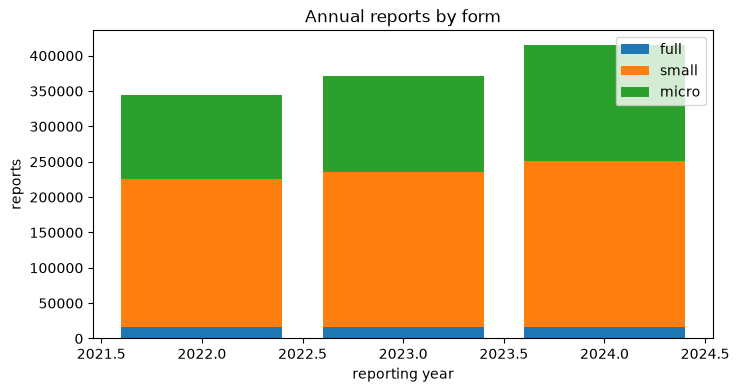

In [10]:
counts = (reports.group_by('year', 'form').len()
          .pivot(on='form', index='year', values='len').sort('year'))
display(counts)

plot_counts = counts.fill_null(0)
forms = [c for c in ['full', 'small', 'micro'] if c in plot_counts.columns]
bottom = np.zeros(plot_counts.height)
fig, ax = plt.subplots(figsize=(8, 4))
for form in forms:
    values = plot_counts[form].to_numpy()
    ax.bar(plot_counts['year'].to_numpy(), values, bottom=bottom, label=form)
    bottom += values
ax.set(title='Annual reports by form', xlabel='reporting year', ylabel='reports')
ax.legend(); plt.show()

### Висновок

Кількість звітів зросла з 343 985 у 2022 році до 414 900 у 2024 році. Основне зростання забезпечили мікроформи: 118 103 → 163 991. Кількість повних форм зменшилася: 16 840 → 15 969. Отже, загальну якість моделей переважно визначають малі та мікропідприємства.

## 3. Розподіл доходу

### Підхід

Дохід аналізується у вихідному масштабі та після `log1p`. Окремо оцінюються нульові, від’ємні й відсутні значення.

year,non_missing,zero,negative,median_y,median_z
i64,u32,u32,u32,f64,f64
2022,242439,5708,69,1707.8000,7.4444
2023,248382,8517,77,2183.4000,7.6902
2024,261181,12125,66,2379.4000,7.7761


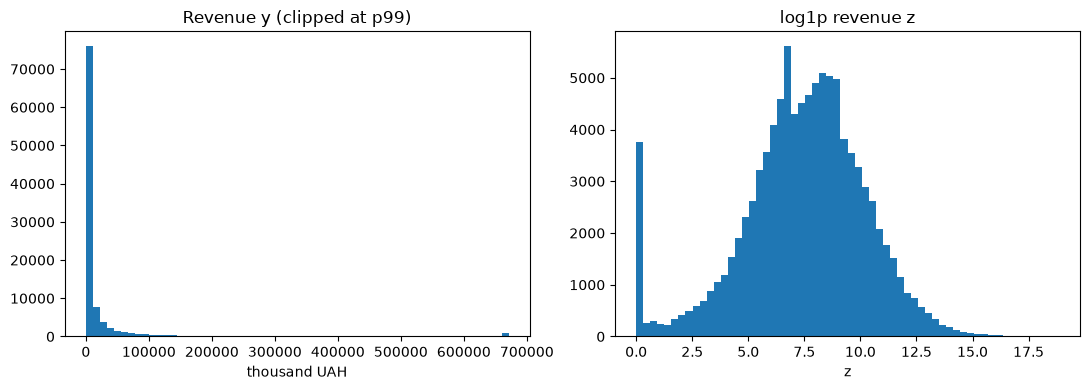

In [11]:
revenue = reports.filter(pl.col('revenue').is_not_null())
revenue_summary = revenue.group_by('year').agg(
    pl.len().alias('non_missing'),
    (pl.col('revenue') == 0).sum().alias('zero'),
    (pl.col('revenue') < 0).sum().alias('negative'),
    pl.col('revenue').median().alias('median_y'),
    pl.col('revenue').filter(pl.col('revenue') >= 0).log1p().median().alias('median_z'),
).sort('year')
display(revenue_summary)

sample_y = (revenue.filter(pl.col('revenue') >= 0)
            .sample(fraction=min(1.0, 100_000 / max(revenue.height, 1)), seed=42)
            ['revenue'].to_numpy())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(np.clip(sample_y, 0, np.quantile(sample_y, .99)), bins=60)
axes[0].set(title='Revenue y (clipped at p99)', xlabel='thousand UAH')
axes[1].hist(np.log1p(sample_y), bins=60)
axes[1].set(title='log1p revenue z', xlabel='z')
plt.tight_layout(); plt.show()

### Висновок

Медіанний номінальний дохід зріс з 1,709 млн грн у 2022 році до 2,382 млн грн у 2024 році, але вихідний розподіл сильно асиметричний. `log1p` зменшує вплив найбільших підприємств і є придатною шкалою для MAE. Частка відсутнього доходу зросла з 29,5% до 37,0%, а нульового — з 2,4% до 4,6%, тому видалення неповних рядків суттєво змінило б популяцію.

## 4. Динаміка панелі та персистентність

### Підхід

Оцінюються входи й виходи підприємств, динаміка реального `z`, кореляція `z_t` із `z_{t+1}` та відхилення від лінії персистентності.

from,to,entrants,exits,continuing
i64,i64,i64,i64,i64
2022,2023,62774,35365,308620
2023,2024,75440,31934,339460


t,median_z,mean_z,n
i64,f64,f64,u32
2021,7.8414,7.7884,233830
2022,7.4117,7.3797,219144
2023,7.5564,7.4895,225730


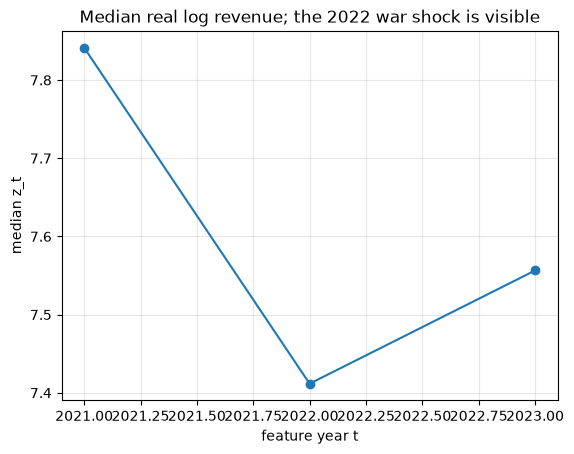

target_year,corr_z_t_z_next,n
i64,f64,u32
2022,0.7690,233830
2023,0.7878,219144
2024,0.8064,225730


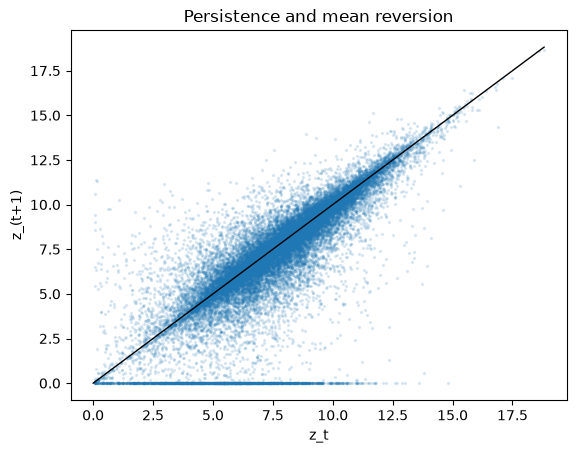

In [12]:
year_sets = {y: set(reports.filter(pl.col('year') == y)['edrpou'].to_list())
             for y in sorted(reports['year'].unique().to_list())}
flows = []
for previous, current in zip(sorted(year_sets)[:-1], sorted(year_sets)[1:]):
    flows.append({'from': previous, 'to': current,
                  'entrants': len(year_sets[current] - year_sets[previous]),
                  'exits': len(year_sets[previous] - year_sets[current]),
                  'continuing': len(year_sets[current] & year_sets[previous])})
display(pl.DataFrame(flows))

panel_year = panel.group_by('t').agg(
    pl.col('z_t').median().alias('median_z'),
    pl.col('z_t').mean().alias('mean_z'),
    pl.len().alias('n'),
).sort('t')
display(panel_year)
plt.plot(panel_year['t'], panel_year['median_z'], marker='o')
plt.title('Median real log revenue; the 2022 war shock is visible')
plt.xlabel('feature year t'); plt.ylabel('median z_t'); plt.grid(alpha=.3); plt.show()

correlations = panel.group_by('target_year').agg(
    pl.corr('z_t', 'z_next').alias('corr_z_t_z_next'), pl.len().alias('n')
).sort('target_year')
display(correlations)
scatter = panel.sample(n=min(30_000, panel.height), seed=42)
plt.scatter(scatter['z_t'], scatter['z_next'], s=2, alpha=.12)
line = [float(min(scatter['z_t'].min(), scatter['z_next'].min())),
        float(max(scatter['z_t'].max(), scatter['z_next'].max()))]
plt.plot(line, line, color='black', linewidth=1)
plt.xlabel('z_t'); plt.ylabel('z_(t+1)'); plt.title('Persistence and mean reversion'); plt.show()

### Висновок

Панель незбалансована: у 2023 році з’явилося 62 774 підприємства і вибуло 35 365; у 2024 році — 75 440 і 31 934 відповідно. Медіана реального `z` впала з 7,841 у 2021 році до 7,412 у 2022 році, після чого відновилася до 7,556 у 2023 році. Медіанна зміна 2022 року дорівнює −0,463, тобто приблизно −37%, тоді як у 2023–2024 роках вона близька до +4%. Кореляція `z_t` і `z_{t+1}` становить 0,77–0,81, тому персистентність є сильним базовим прогнозом. Фільтрація лише постійно присутніх підприємств створила б survivor bias.

## 5. Аномалії та пропуски

### Підхід

Позначаються різниця масштабу ×1000, незбіг балансу, зміна доходу понад 10 разів і нульовий або порожній дохід. Прапорці приєднуються до панелі окремим join. Пропуски аналізуються за типом форми; для M2 заповнення й масштабування навчаються лише на train.

In [13]:
flagged_reports = add_anomaly_flags(reports)
flag_summary = flagged_reports.select(
    pl.len().alias('reports'),
    *[pl.col(c).mean().alias(c) for c in FLAG_COLUMNS + ['has_anomaly']],
)
display(flag_summary)
display(flagged_reports.group_by('year', 'form').agg(
    *[pl.col(c).mean().alias(c) for c in FLAG_COLUMNS + ['has_anomaly']],
    pl.len().alias('n'),
).sort('year', 'form'))

missing_columns = ['revenue', 'assets', 'equity', 'lt_liab', 'cur_liab', 'net_result', 'employees', 'kved', 'obl']
missing_by_form = reports.group_by('year', 'form').agg(
    *[pl.col(c).is_null().mean().alias(c) for c in missing_columns],
    pl.len().alias('n'),
).sort('year', 'form')
display(missing_by_form)

flags = flags_for_panel(flagged_reports)
flags.write_parquet(OUT / 'anomaly_flags_B.parquet')
panel_b = attach_flags(panel, flags)
print('clean panel share:', f'{panel_b.select((~pl.col("has_anomaly")).mean()).item():.1%}')

reports,flag_units_x1000,flag_balance_mismatch,flag_extreme_growth,flag_zero_revenue,has_anomaly
u32,f64,f64,f64,f64,f64
1130279,0.0005,0.0001,0.0392,0.3580,0.3974


year,form,flag_units_x1000,flag_balance_mismatch,flag_extreme_growth,flag_zero_revenue,has_anomaly,n
i64,str,f64,f64,f64,f64,f64,u32
2022,"""full""",0.0010,0.0014,0.0374,0.1830,0.2210,16840
2022,"""micro""",0.0008,0.0000,0.0471,0.3969,0.4442,118103
2022,"""small""",0.0005,0.0001,0.0520,0.2741,0.3264,209042
2023,"""full""",0.0012,0.0014,0.0361,0.1921,0.2291,16208
2023,"""micro""",0.0011,0.0000,0.0356,0.4426,0.4785,136453
2023,"""small""",0.0007,0.0001,0.0402,0.3110,0.3515,218733
2024,"""full""",0.0000,0.0013,0.0280,0.1996,0.2279,15969
2024,"""micro""",0.0000,0.0000,0.0281,0.4892,0.5173,163991
2024,"""small""",0.0000,0.0001,0.0337,0.3508,0.3846,234940


year,form,revenue,assets,equity,lt_liab,cur_liab,net_result,employees,kved,obl,n
i64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,u32
2022,"""full""",0.1796,0.0143,0.0182,0.0745,0.0209,0.0268,1.0000,0.0000,0.0033,16840
2022,"""micro""",0.3728,0.0712,0.1439,0.8131,0.1510,0.1896,0.0382,0.0000,0.0000,118103
2022,"""small""",0.2607,0.0695,0.0876,0.8283,0.1167,0.1254,0.0218,0.0000,0.0000,209042
2023,"""full""",0.1877,0.0138,0.0180,0.0735,0.0223,0.0292,1.0000,0.0000,0.0031,16208
2023,"""micro""",0.4102,0.0833,0.1709,0.8000,0.1735,0.2228,0.0380,0.0001,0.0000,136453
2023,"""small""",0.2926,0.0846,0.1083,0.8271,0.1393,0.1532,0.0254,0.0000,0.0000,218733
2024,"""full""",0.1954,0.0180,0.0217,0.0778,0.0271,0.0331,1.0000,0.0001,0.0036,15969
2024,"""micro""",0.4468,0.1044,0.2112,0.7802,0.2095,0.2559,0.0418,0.0000,0.0000,163991
2024,"""small""",0.3291,0.1166,0.1482,0.8238,0.1819,0.1962,0.0314,0.0000,0.0000,234940


clean panel share: 95.9%


### Висновок

На сирих звітах 39,7% рядків мають хоча б один прапорець, переважно через нульовий або порожній дохід — 35,8%. Екстремальний ріст має 3,9% рядків, тоді як ×1000 і незбіг балансу трапляються лише у 0,05% і 0,01%. Після формування модельної популяції «чистими» залишаються 95,9% рядків. Найбільше пропусків у мікроформах; довгострокові зобов’язання відсутні приблизно у 80% малих і мікроформ. Прапорець ×1000 для 2024 року не визначається, бо для його перевірки потрібен заборонений файл 2025 року; на тестові ознаки це не впливає.

## 6. Агрегація та концентрація

### Підхід

Рахується сумарний дохід за роками й секціями КВЕД та частка топ-1% підприємств у загальній сумі.

year,kved_section,revenue_sum,reports
i64,str,f64,u32
2022,"""G""",4619870860.8680,78081
2022,"""C""",1791161993.6690,32659
2022,"""D""",1516587183.9000,3483
2022,"""A""",709709051.2800,35052
2022,"""O""",690713734.2000,769
2022,"""H""",499875838.5500,15203
2022,"""B""",471415915.8000,1496
2022,"""M""",340653001.2250,23611
2022,"""J""",287610874.1600,13528


year,positive_firms,top_1pct_share
i64,i64,f64
2022,236662,0.6868
2023,239788,0.6701
2024,248990,0.6551


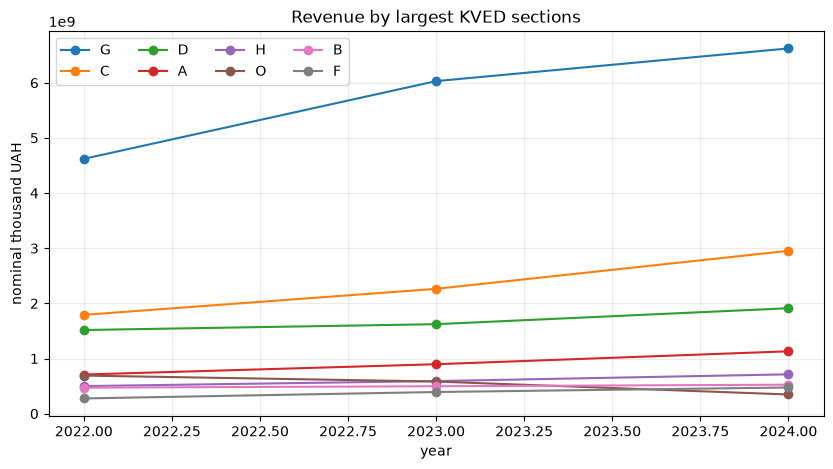

In [14]:
raw_with_section = reports.with_columns(kved_section_expr().alias('kved_section'))
sector_totals = (raw_with_section.group_by('year', 'kved_section')
                 .agg(pl.col('revenue').filter(pl.col('revenue') >= 0).sum().alias('revenue_sum'),
                      pl.len().alias('reports'))
                 .sort('year', 'revenue_sum', descending=[False, True]))
display(sector_totals)

concentration = []
for year in sorted(reports['year'].unique().to_list()):
    values = reports.filter((pl.col('year') == year) & (pl.col('revenue') > 0))['revenue'].to_numpy()
    cutoff = np.quantile(values, .99)
    concentration.append({'year': year, 'positive_firms': len(values),
                          'top_1pct_share': float(values[values >= cutoff].sum() / values.sum())})
display(pl.DataFrame(concentration))

top_sections = (sector_totals.group_by('kved_section').agg(pl.col('revenue_sum').sum())
                .sort('revenue_sum', descending=True).head(8)['kved_section'].to_list())
plot_sector = sector_totals.filter(pl.col('kved_section').is_in(top_sections))
fig, ax = plt.subplots(figsize=(10, 5))
for section in top_sections:
    part = plot_sector.filter(pl.col('kved_section') == section).sort('year')
    ax.plot(part['year'], part['revenue_sum'], marker='o', label=section)
ax.set(title='Revenue by largest KVED sections', xlabel='year', ylabel='nominal thousand UAH')
ax.legend(ncol=4); ax.grid(alpha=.25); plt.show()

### Висновок

Топ-1% підприємств формує 68,7% доходу у 2022 році, 67,0% у 2023 році та 65,5% у 2024 році. Найбільші суми припадають на торгівлю G, промисловість C, енергетику D і сільське господарство A. Через таку концентрацію `MAE_log` описує типову помилку підприємства, а `WAPE` значною мірою залежить від кількох великих компаній. Для прогнозування агрегованих сум потрібна окрема перевірка великих підприємств.

## 7. M2 Ridge та крос-валідація

### Підхід

M2 прогнозує `Δz` і додає прогноз до `z_t`. Офіційна оцінка використовує expanding-window фолди F1 і F2. Додаткова п’ятифолдова `GroupKFold` за ЄДРПОУ виконується лише всередині train та порівнює `alpha` 0.1, 1, 10 і 100. Офіційне значення залишається `alpha=1`.

In [15]:
if RUN_INNER_CV:
    cv_source = panel_b.filter(
        pl.col('target_year').is_in(FOLDS['F2'][0])
        & (pl.col('edrpou').hash(seed=42) % CV_SAMPLE_MODULUS == 0)
    )
    cv_results = group_cv_m2(cv_source, alphas=(0.1, 1.0, 10.0, 100.0), n_splits=5)
    cv_summary = (cv_results.group_by('alpha').agg(
        pl.col('MAE_log').mean().alias('MAE_log_mean'),
        pl.col('MAE_log').std().alias('MAE_log_sd'),
        pl.col('Skill').mean().alias('Skill_mean'),
    ).sort('MAE_log_mean'))
    display(cv_summary)
    cv_results.write_parquet(OUT / 'cv_B.parquet')
else:
    cv_results = pl.DataFrame()

results_b, m2_predictions = evaluate_m2(panel_b, alpha=1.0)
display(results_b.sort('population', 'fold'))
results_b.write_parquet(OUT / 'results_B.parquet')

alpha,MAE_log_mean,MAE_log_sd,Skill_mean
f64,f64,f64,f64
100.0000,1.1378,0.0221,-0.0000
10.0000,1.1387,0.0221,-0.0008
1.0000,1.1390,0.0222,-0.0010
0.1000,1.1390,0.0222,-0.0011


model,fold,population,MAE_log,Bias,MdAPE,WAPE,n,Skill
str,str,str,f64,f64,f64,f64,i64,f64
"""M2""","""F1""","""all""",1.4925,-0.6837,0.6840,0.6779,219144,-0.4571
"""M2""","""F2""","""all""",1.4887,-0.8653,0.7004,0.7624,225730,-0.6497
"""M2""","""F1""","""clean""",1.4275,-0.7008,0.6758,0.6703,204234,-0.5260
"""M2""","""F2""","""clean""",1.4447,-0.8665,0.6935,0.7566,212769,-0.7126


### Висновок

У внутрішній CV результати майже не залежать від `alpha`: середній MAE змінюється лише від 1,1390 для `alpha=0.1` до 1,1378 для `alpha=100`, а середній Skill залишається близьким до нуля. На часових фолдах M2 значно гірша: F1 має `MAE_log=1,492`, `Bias=−0,684`, `Skill=−0,457`; F2 — `MAE_log=1,489`, `Bias=−0,865`, `Skill=−0,650`. На «чистій» популяції MAE трохи зменшується, але Skill погіршується. Отже, проблема не у виборі `alpha`: модель переносить негативну зміну шокового 2022 року на період відновлення і систематично занижує дохід.

## 8. Вибір моделі та сегменти

### Підхід

N1, M1 і M2 порівнюються за середнім `MAE_log` на F1–F2. Для M1 та найкращої моделі рахуються `MAE_log` і `Bias` за формою та секцією КВЕД. Сегменти з дуже малою кількістю спостережень не інтерпретуються.

In [16]:
comparison_rows, fold_predictions = [], []
for fold, (train_years, test_year) in FOLDS.items():
    train = panel_b.filter(pl.col('target_year').is_in(train_years))
    pred = add_m1_prediction(train, m2_predictions[fold]).with_columns(pl.col('z_t').alias('N1'))
    fold_predictions.append(pred.with_columns(pl.lit(fold).alias('fold')))
    for model in ['N1', 'M1', 'M2']:
        comparison_rows.append({'model': model, 'fold': fold,
                                **regression_metrics(pred['z_next'], pred[model], pred['N1'])})

comparison = pl.DataFrame(comparison_rows)
display(comparison.sort('fold', 'model'))
ranking = comparison.group_by('model').agg(pl.col('MAE_log').mean().alias('mean_MAE_log')).sort('mean_MAE_log')
display(ranking)
best_model = ranking[0, 'model']
all_predictions = pl.concat(fold_predictions, how='vertical_relaxed')

m1_segments = segment_metrics(all_predictions, 'M1')
best_segments = segment_metrics(all_predictions, best_model)
segments_b = pl.concat([
    m1_segments.with_columns(pl.lit('M1 demonstration').alias('analysis')),
    best_segments.with_columns(pl.lit('best available model').alias('analysis')),
], how='vertical_relaxed')
display(segments_b.sort('analysis', 'segment', 'MAE_log'))
segments_b.write_parquet(OUT / 'segments_B.parquet')
print('Best available model:', best_model)

model,fold,MAE_log,Bias,MdAPE,WAPE,n,Skill
str,str,f64,f64,f64,f64,i64,f64
"""M1""","""F1""",1.4457,-0.5871,0.6558,0.7332,219144,-0.4114
"""M2""","""F1""",1.4925,-0.6837,0.6840,0.6779,219144,-0.4571
"""N1""","""F1""",1.0243,0.2745,0.3468,0.3744,219144,0.0000
"""M1""","""F2""",1.1707,-0.3664,0.5316,0.6633,225730,-0.2974
"""M2""","""F2""",1.4887,-0.8653,0.7004,0.7624,225730,-0.6497
"""N1""","""F2""",0.9024,0.2155,0.2969,0.3770,225730,0.0000


model,mean_MAE_log
str,f64
"""N1""",0.9634
"""M1""",1.3082
"""M2""",1.4906


model,segment,segment_value,MAE_log,Bias,n,analysis
str,str,str,f64,f64,u32,str
"""M1""","""form""","""full""",1.2503,-0.5916,25742,"""M1 demonstration"""
"""M1""","""form""","""small""",1.2928,-0.4820,282239,"""M1 demonstration"""
"""M1""","""form""","""micro""",1.3444,-0.4390,136893,"""M1 demonstration"""
"""M1""","""kved_section""","""E""",1.0828,-0.6018,4392,"""M1 demonstration"""
"""M1""","""kved_section""","""L""",1.0999,-0.5666,46363,"""M1 demonstration"""
"""M1""","""kved_section""","""O""",1.1393,-0.6441,424,"""M1 demonstration"""
"""M1""","""kved_section""","""P""",1.1553,-0.5887,4983,"""M1 demonstration"""
"""M1""","""kved_section""","""Q""",1.1613,-0.5701,11626,"""M1 demonstration"""
"""M1""","""kved_section""","""A""",1.1724,-0.7316,56482,"""M1 demonstration"""


Best available model: N1


### Висновок

Найкращою моделлю залишається N1. Для повної форми її `MAE_log` дорівнює 0,745, для малої — 0,945, для мікро — 1,039: прогнозованість погіршується зі зменшенням підприємства. Серед достатньо великих секцій КВЕД найнижчі помилки мають E, L, Q та A, а найвищі — K і F. N1 переважно має позитивний Bias і завищує наступний дохід, тоді як M1 має негативний Bias і недооцінює відновлення. Жодна навчена модель не виконує правило `Skill > 0` в обох часових фолдах.

## 9. Підсумковий висновок і напрям оптимізації

### Підхід

Робочою вважається модель із `Skill > 0` у F1 і F2; серед робочих обирається мінімальний середній `MAE_log`. Наступні експерименти мають оцінюватися на тих самих зовнішніх часових фолдах без підбору за тестовими роками.

### Висновок

Жодна навчена модель не перевершила N1 в обох фолдах. Головні причини — сильна персистентність доходу, структурний шок 2022 року та лише два часові фолди. Подальший перебір `alpha` для Ridge малоперспективний. Доцільніше перевірити ансамбль N1 з моделлю поправки, L1 або Huber loss, квантильні прогнози та окрему обробку великих підприємств. Під час переходу назад через `expm1` потрібно враховувати, що прогноз відповідає умовній медіані й може занижувати агреговані суми.